# ESC-50: Transfer Robustness and Matched MLP Heads

## Summary

The fixed frozen PANNs system reaches **69.85% accuracy at 10 dB**, compared with **61.56%** for the mean of three noise-trained CNNs. Its paired advantage is **+8.29 pp [1.83, 14.74]**, conditional on these models, sources and noise realizations. However, PANNs loses **21.36 pp** from clean audio, versus **11.56 pp** for noise-trained CNNs: higher absolute noisy accuracy and smaller degradation are different outcomes.

A separate six-fit head experiment finds **89.78% clean accuracy for the ReLU MLP**, versus **91.12% for its matched factorized-linear control**. These results do not support replacing the existing 91.21% logistic head with this MLP configuration.

This notebook executes the fixed experiment and displays its predictions, metrics, source intervals, training curves, per-class recall and the restored earlier CNN/MLP controls. The [complete project notebook](ESC50_Results.ipynb) retains the original study and all 22 original scientific figures.

## 1. Research review and fixed questions

| Completed research | What the evidence supports | Remaining boundary |
| --- | --- | --- |
| CNN, BiGRU, attention: three fixed seeds | Small uncertain channel-attention gain | No universal attention or recurrent advantage |
| Earlier pooled/tokenwise CNN-MLP controls | Capacity controls were completed and are restored below | They are not PANNs heads |
| Augmentation: 54 stress conditions | Noise training helps the tested Gaussian perturbation | Historical noise draws differ from this new panel |
| Feature study: 12 settings × three seeds | Representation effects within a smaller pooled CNN | Not directly transferable to the main encoder |
| Encoder-token interventions: 30 conditions | BiGRU reversal sensitivity; CNN pooling invariance | Not raw-audio temporal causality |
| Frozen PANNs + logistic regression | Stronger clean development-system performance | External data, model capacity and frontend differ |

### Primary question

On the same newly generated 10 dB recordings, does frozen PANNs + the existing logistic head outperform the mean of the three existing noise-trained CNNs?

The primary estimand is the paired **absolute noisy-accuracy difference**. Clean-to-noisy accuracy loss is secondary. The original head and all four backbones remain frozen. No parameter selection follows the new robustness result.

### Secondary question

Does inserting ReLU into a fixed `2048 → 49 → 50` head help? The factorized-linear and ReLU heads both have **102,901 parameters**, identical paired initial weights and minibatch ordering for seeds 101/202/303. Both use AdamW (lr 0.001, weight decay 0.0001), batch size 32, gradient clipping 5, **100 fixed epochs**, no dropout or scheduler. Only final-epoch weights are evaluated; there is no validation checkpoint selection.

Without ReLU, the layers compose into an affine map of rank at most 49. This does **not** restrict the family of 50-class affine softmax probabilities: subtracting the common logit leaves softmax unchanged, and the centered weight matrix has rank at most 49. Any such classifier therefore has an equivalent 49-hidden linear factorization. The contrast concerns the activation change under matched parameterization and training, not an assumed lack of linear classifier capacity. The original L-BFGS logistic head is a separate system reference, not a matched-optimizer nonlinearity control.

### Evaluation scope

1,200 training clips; 398 validation clips from 295 sources. Source isolation uses metadata recording IDs. All official folds have historical exposure; AudioSet overlap is unresolved. These are development experiments, not independent confirmation. Four thousand paired source-cluster resamples retain all clips of each sampled source and use their actual clip-count denominator. Fixed training seeds are not extra independent audio recordings.

For the centering matrix $C=I-\mathbf{1}\mathbf{1}^{T}/50$, $\operatorname{softmax}(z)=\operatorname{softmax}(Cz)$ and $\operatorname{rank}(CW)\leq49$. The rank statement concerns logits; common-offset invariance explains why the affine softmax family is preserved.

In [1]:
from pathlib import Path
import os,sys,json,subprocess
from datetime import datetime,timezone
RUN_EXPERIMENT = True
candidates=[Path.cwd(),Path.cwd().parent,Path.cwd()/"research/esc50_improvements",Path("/content/esc50_followup")]
ROOT=next((p for p in candidates if (p/"scripts/run_transfer_followup.py").exists()),None)
if ROOT is None:
    ROOT=Path("/content/esc50_followup")
    subprocess.run(["git","clone","--depth","1","https://github.com/Richardafcs/esc-50-sound-classification.git",str(ROOT)],check=True,capture_output=True,timeout=180)
os.chdir(ROOT);sys.path.insert(0,str(ROOT/"src"))
print("Execution started (UTC):",datetime.now(timezone.utc).isoformat())
print("Project:",ROOT.name)

Execution started (UTC): 2026-11-05T03:37:15.950998+00:00
Project: esc50_followup


In [2]:
subprocess.run([sys.executable,"-m","pip","install","-q","numpy>=2,<3","pandas>=2.2,<3","matplotlib>=3.9,<4","scikit-learn==1.6.1","torchlibrosa==0.1.0","librosa==0.11.0","soundfile>=0.13,<1","joblib>=1.4,<2"],check=True,capture_output=True,text=True,timeout=360)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display,Markdown
from esc50_sound.prediction_errors import paired_correctness
plt.rcParams.update({"figure.figsize":(10,5),"font.size":11,"axes.spines.top":False,"axes.spines.right":False})
def table(frame,precision=3):
    display(frame.style.format(precision=precision,na_rep="—").hide(axis="index").set_properties(**{"white-space":"normal","text-align":"left","max-width":"220px"}))
def read_table(name):return pd.read_csv(DATA/name)
print("Runtime:",torch.__version__,np.__version__,torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Runtime: 2.11.0+cu130 2.4.6 Tesla T4


## 2. Prepare official inputs and execute

A fresh Colab run downloads the official data and PANNs backbone, reuses the published small heads/checkpoints and performs the fixed experiment. If clean training embeddings are locally available, they are reused; otherwise they are extracted once without updating the backbone. All models receive the **same perturbed waveform before their own frontend**.

The seed-sequence-v2 perturbations are a new panel. The historical 61.31% noise-CNN result is not substituted for the new matched comparison. A completed output directory is reused rather than silently fitting six more heads.

In [3]:
import urllib.request,zipfile
ASSETS=Path("/content/esc50_panns") if Path("/content").exists() else ROOT/"results/panns_assets"
if RUN_EXPERIMENT:
    if not torch.cuda.is_available():raise RuntimeError("Select a Colab GPU runtime, or set RUN_EXPERIMENT=False to inspect the published results.")
    ASSETS.mkdir(parents=True,exist_ok=True)
    repository=ASSETS/"audioset_tagging_cnn"
    if not repository.exists():subprocess.run(["git","clone","https://github.com/qiuqiangkong/audioset_tagging_cnn.git",str(repository)],check=True,capture_output=True,timeout=180)
    checkpoint=ASSETS/"Cnn14_16k_mAP=0.438.pth"
    if not checkpoint.exists():urllib.request.urlretrieve("https://zenodo.org/records/3987831/files/Cnn14_16k_mAP%3D0.438.pth?download=1",checkpoint)
    dataset=ASSETS/"ESC-50"
    if not (dataset/"audio").exists():
        archive=ASSETS/"esc50.zip"
        urllib.request.urlretrieve("https://codeload.github.com/karolpiczak/ESC-50/zip/refs/heads/master",archive)
        with zipfile.ZipFile(archive) as zipped:
            for member in zipped.infolist():
                relative=Path(*Path(member.filename).parts[1:])
                if relative.parts and relative.parts[0] in ("audio","meta") and not member.is_dir():
                    destination=dataset/relative;destination.parent.mkdir(parents=True,exist_ok=True);destination.write_bytes(zipped.read(member))
    print("Official model and audio inputs are ready.")
else:print("Published-result mode: no inference or fitting.")

Official model and audio inputs are ready.


In [4]:
DATA=ROOT/"results/transfer_followup" if RUN_EXPERIMENT else ROOT/"reports/transfer_followup_20261105"
if RUN_EXPERIMENT:
    command=[sys.executable,"-u",str(ROOT/"scripts/run_transfer_followup.py"),"--assets",str(ASSETS),"--output",str(DATA),"--device","cuda"]
    environment=os.environ.copy();environment.update(OMP_NUM_THREADS="1",OPENBLAS_NUM_THREADS="1",MKL_NUM_THREADS="1")
    process=subprocess.run(command,capture_output=True,text=True,env=environment,timeout=1600)
    print(process.stdout[-2500:])
    if process.returncode:print(process.stderr[-4000:]);process.check_returncode()
summary=json.loads((DATA/"summary.json").read_text())
print("Status:",summary["status"],"| clips:",summary["clips"],"| sources:",summary["sources"])
print("New head fits:",summary["head_fits"],"| fixed epochs:",summary["head_epochs"])
print("Experiment seconds:",round(summary["total_seconds"],2),"(excludes setup/download)")
print("Test WAVs evaluated:",summary["test_waveforms_read"])
print("Measured added-noise SNR (dB):",summary["realized_snr"])
print("Clean label changes from the earlier runtime:",summary["clean_prediction_changes_from_previous"])
FIGURES=ROOT/"reports/transfer_followup_20261105";FIGURES.mkdir(parents=True,exist_ok=True)

Completed fixed experiment already exists; reading its saved outputs is sufficient.

Status: completed | clips: 398 | sources: 295
New head fits: 6 | fixed epochs: 100
Experiment seconds: 88.73 (excludes setup/download)
Test WAVs evaluated: 0
Measured added-noise SNR (dB): {'min_db': 9.999998779390856, 'max_db': 10.000001335198675, 'mean_db': 10.00000007271402}
Clean label changes from the earlier runtime: {'noise_cnn_s101': 0, 'noise_cnn_s202': 0, 'noise_cnn_s303': 0, 'panns_lr': 0}


## 3. Primary matched robustness comparison

Accuracy and macro-F1 are calculated from the saved predictions. Noise-CNN and neural-head summaries use three fixed fits; the original logistic head uses one fit. Error bars below are **sample SD across fixed fits**, not source confidence intervals.

In [5]:
groups=read_table("groups.csv")
labels={"panns_lr":"PANNs + logistic","noise_cnn":"Noise-trained CNN","factorized_linear":"PANNs + factorized linear","mlp_relu":"PANNs + ReLU MLP"}
comparison=groups.copy();comparison["model"]=comparison["model"].map(labels)
comparison.columns=["System","Condition","Fits","Accuracy (%)","SD (pp)","Macro-F1 (%)","F1 SD (pp)"]
table(comparison,2)
table(read_table("metrics.csv"),4)

System,Condition,Fits,Accuracy (%),SD (pp),Macro-F1 (%),F1 SD (pp)
PANNs + logistic,clean,1,91.21,—,91.10,—
PANNs + logistic,snr_10,1,69.85,—,71.53,—
Noise-trained CNN,clean,3,73.12,0.87,71.99,1.23
Noise-trained CNN,snr_10,3,61.56,2.30,59.21,1.88
PANNs + factorized linear,clean,3,91.12,1.05,91.05,1.01
PANNs + factorized linear,snr_10,3,68.76,0.95,69.91,1.23
PANNs + ReLU MLP,clean,3,89.78,0.95,89.70,0.95
PANNs + ReLU MLP,snr_10,3,67.34,0.87,68.19,0.85


model,seed,condition,accuracy,macro_f1,correct,clips,parameters
panns_lr,0,clean,0.9121,0.9110,363,398,102450
noise_cnn,101,clean,0.7261,0.7128,289,398,49058
noise_cnn,202,clean,0.7412,0.7341,295,398,49058
noise_cnn,303,clean,0.7261,0.7129,289,398,49058
panns_lr,0,snr_10,0.6985,0.7153,278,398,102450
noise_cnn,101,snr_10,0.6206,0.5922,247,398,49058
noise_cnn,202,snr_10,0.5905,0.5732,235,398,49058
noise_cnn,303,snr_10,0.6357,0.6108,253,398,49058
factorized_linear,101,clean,0.9146,0.9139,364,398,102901
factorized_linear,101,snr_10,0.6834,0.7000,272,398,102901


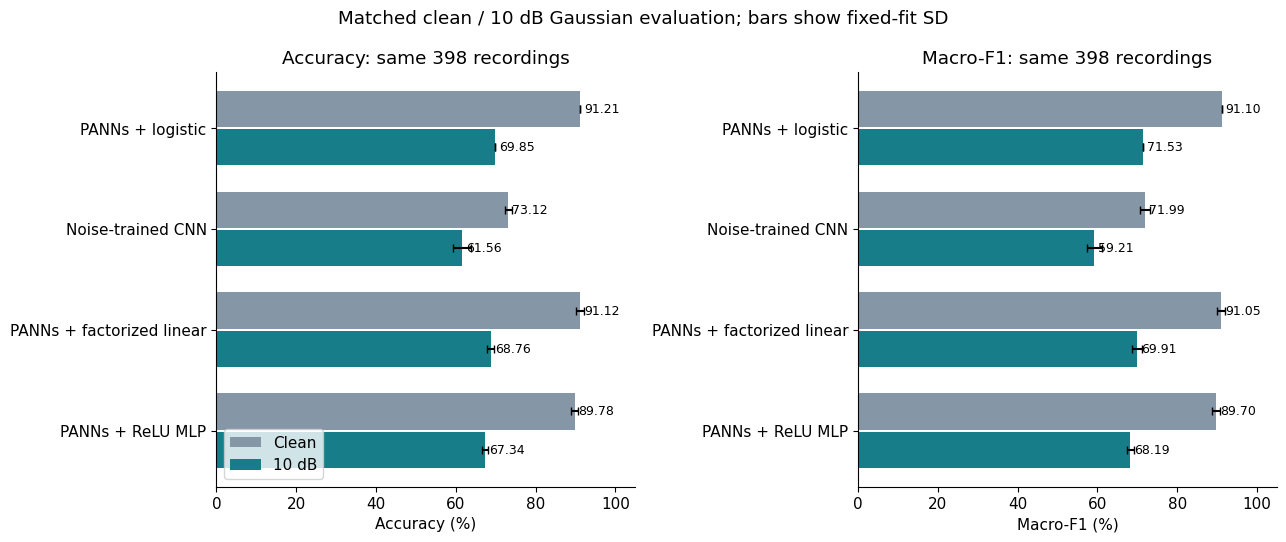

In [6]:
systems=list(labels)
fig,axes=plt.subplots(1,2,figsize=(13,5.5))
for ax,metric,sd,title in [(axes[0],"accuracy_percent","accuracy_sd_pp","Accuracy"),(axes[1],"macro_f1_percent","macro_f1_sd_pp","Macro-F1")]:
    for offset,condition,color in [(-.19,"clean","#8597a6"),(.19,"snr_10","#177e89")]:
        part=groups[groups.condition==condition].set_index("model").loc[systems]
        ax.barh(np.arange(4)+offset,part[metric],height=.36,color=color,label="Clean" if condition=="clean" else "10 dB")
        ax.errorbar(part[metric],np.arange(4)+offset,xerr=part[sd].fillna(0),fmt="none",ecolor="black",capsize=3)
        for index,value in enumerate(part[metric]):ax.text(value+1,index+offset,f"{value:.2f}",va="center",fontsize=9)
    ax.set_yticks(range(4),[labels[s] for s in systems]);ax.invert_yaxis();ax.set_xlim(0,105);ax.set_xlabel(title+" (%)");ax.set_title(title+": same 398 recordings")
axes[0].legend(loc="lower left")
fig.suptitle("Matched clean / 10 dB Gaussian evaluation; bars show fixed-fit SD")
fig.tight_layout();fig.savefig(FIGURES/"matched_robustness.png",dpi=180);plt.show()

In [7]:
effects=read_table("paired_effects.csv");losses=read_table("accuracy_losses.csv")
table(effects,3)
loss_display=losses.copy();loss_display["model"]=loss_display["model"].map(labels)
loss_display.columns=["System","Accuracy loss (pp)","95% lower (pp)","95% upper (pp)"]
table(loss_display,3)

comparison,condition,delta_pp,low_pp,high_pp
panns_lr_minus_noise_cnn,clean,18.090,13.350,22.954
mlp_relu_minus_factorized_linear,clean,-1.340,-2.519,-0.260
factorized_linear_minus_panns_lr,clean,-0.084,-1.420,1.231
mlp_relu_minus_panns_lr,clean,-1.424,-3.159,0.163
panns_lr_minus_noise_cnn,snr_10,8.291,1.827,14.739
mlp_relu_minus_factorized_linear,snr_10,-1.424,-3.046,0.243
factorized_linear_minus_panns_lr,snr_10,-1.089,-2.917,0.597
mlp_relu_minus_panns_lr,snr_10,-2.513,-4.970,-0.087
panns_loss_minus_noise_cnn_loss,clean_to_snr10,9.799,3.193,16.624


System,Accuracy loss (pp),95% lower (pp),95% upper (pp)
PANNs + logistic,21.357,15.980,26.667
Noise-trained CNN,11.558,7.513,15.753
PANNs + factorized linear,22.362,17.349,27.338
PANNs + ReLU MLP,22.446,17.579,27.360


PANNs remains more accurate on the tested noisy recordings: **69.85% versus 61.56%, +8.29 pp [1.83, 14.74]**. Its clean advantage is +18.09 pp, so the noisy advantage is smaller.

PANNs loses **21.36 pp [15.98, 26.67]** from clean to 10 dB; noise-trained CNN loses **11.56 pp [7.51, 15.75]**. The difference in losses is **+9.80 pp [3.19, 16.62]**. This supports higher absolute noisy accuracy for PANNs and fewer points lost for noise-trained CNNs under this panel. It does not isolate an intrinsic robustness property independently of clean performance, training and frontend.

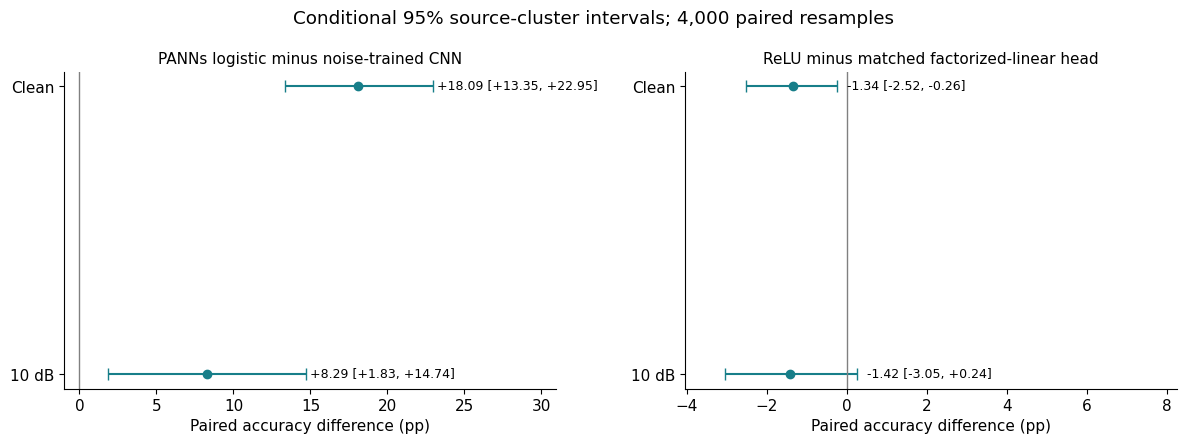

In [8]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,name,title in [(axes[0],"panns_lr_minus_noise_cnn","PANNs logistic minus noise-trained CNN"),(axes[1],"mlp_relu_minus_factorized_linear","ReLU minus matched factorized-linear head")]:
    part=effects[effects.comparison==name]
    for index,row in enumerate(part.itertuples()):
        ax.errorbar(row.delta_pp,index,xerr=[[row.delta_pp-row.low_pp],[row.high_pp-row.delta_pp]],fmt="o",capsize=4,color="#177e89")
        ax.text(row.high_pp+.25,index,f"{row.delta_pp:+.2f} [{row.low_pp:+.2f}, {row.high_pp:+.2f}]",va="center",fontsize=9)
    ax.set_yticks(range(len(part)),["Clean","10 dB"]);ax.axvline(0,color="grey",lw=1);ax.invert_yaxis()
    ax.set_xlim(min(0,part.low_pp.min())-1,part.high_pp.max()+8)
    ax.set_xlabel("Paired accuracy difference (pp)");ax.set_title(title,fontsize=11)
fig.suptitle("Conditional 95% source-cluster intervals; 4,000 paired resamples")
fig.tight_layout();fig.savefig(FIGURES/"paired_transfer_effects.png",dpi=180);plt.show()

## 4. Fixed-budget MLP ablation

Both heads see clean training embeddings only. The noise condition never enters fitting or stopping. All six fits completed 100 epochs and 3,800 optimizer steps. No best seed, width, learning rate or checkpoint is selected after seeing these results.

architecture,seed,condition,parameters,accuracy,macroF1,trainCE,iterations,time_s
factorized_linear,101,clean,102901,0.91457,0.91390,0.00014,3800,8.10097
factorized_linear,101,noise10db,102901,0.68342,0.69998,0.00014,3800,8.10097
factorized_linear,202,clean,102901,0.91960,0.91847,0.00014,3800,8.21126
factorized_linear,202,noise10db,102901,0.68090,0.68638,0.00014,3800,8.21126
factorized_linear,303,clean,102901,0.89950,0.89911,0.00014,3800,8.15673
factorized_linear,303,noise10db,102901,0.69849,0.71085,0.00014,3800,8.15673
mlp_relu,101,clean,102901,0.90201,0.90159,0.00016,3800,7.96980
mlp_relu,101,noise10db,102901,0.67839,0.68928,0.00016,3800,7.96980
mlp_relu,202,clean,102901,0.90452,0.90326,0.00015,3800,8.33850
mlp_relu,202,noise10db,102901,0.67839,0.68382,0.00015,3800,8.33850


Unique completed fits: 6


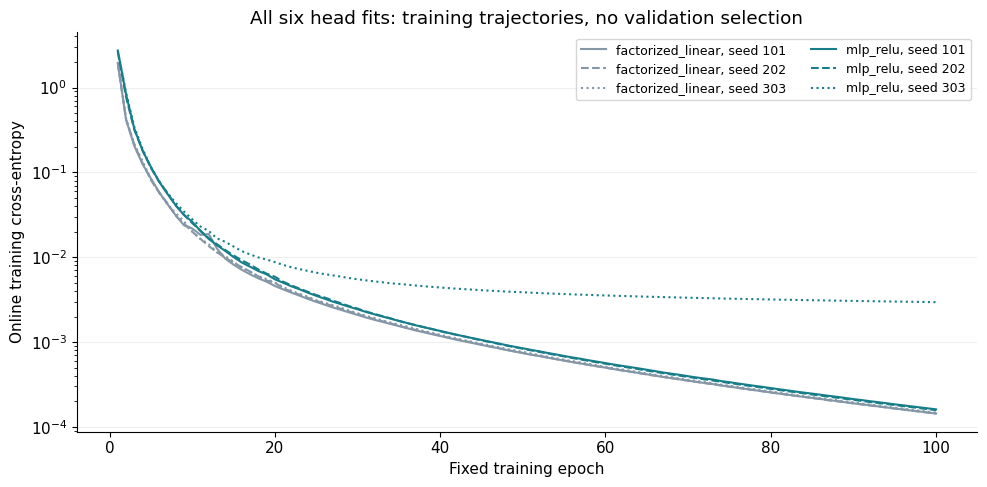

In [9]:
fit_table=read_table("heads/matched_heads_results.csv") if (DATA/"heads/matched_heads_results.csv").exists() else read_table("head_fits.csv")
table(fit_table,5)
print("Unique completed fits:",len(fit_table[["architecture","seed"]].drop_duplicates()))
fig,ax=plt.subplots(figsize=(10,5))
for model,color in [("factorized_linear","#8597a6"),("mlp_relu","#177e89")]:
    for seed,style in [(101,"-"),(202,"--"),(303,":")]:
        file=DATA/"heads"/f"{model}_seed{seed}_history.csv"
        history=pd.read_csv(file if file.exists() else DATA/file.name)
        ax.plot(history.epoch,history.train_ce_online,label=f"{model}, seed {seed}",color=color,linestyle=style)
ax.set_yscale("log");ax.set_xlabel("Fixed training epoch");ax.set_ylabel("Online training cross-entropy")
ax.set_title("All six head fits: training trajectories, no validation selection")
ax.legend(fontsize=9,ncol=2);ax.grid(axis="y",alpha=.2)
fig.tight_layout();fig.savefig(FIGURES/"matched_head_learning_curves.png",dpi=180);plt.show()

The ReLU head averages **89.78%** clean accuracy versus **91.12%** for factorized linear: **−1.34 pp [−2.52, −0.26]**. At 10 dB, the difference is **−1.42 pp [−3.05, +0.24]**, which includes zero.

Against the original logistic system, ReLU is numerically lower on both conditions. Those comparisons also change the optimizer and parameterization. They do not prove that every MLP is worse than logistic regression. The experiment provides no reason to replace the original head with this fixed bottleneck/ReLU configuration. Source intervals are descriptive and conditional; multiple secondary contrasts have no familywise correction.

## 5. Restored earlier CNN/MLP controls

These records come from the completed earlier capacity-control study: shared CNN encoder, parameter-matched pooled MLP and tokenwise MLP, each with three seeds and 60 epochs. They were omitted from a later main table, not left untrained. CNN/BiGRU reference fits overlap the later matrix and are not independent replications. These are not the frozen-PANNs heads fitted above.

model,label,parameters,fits,accuracy_percent,accuracy_sd_pp,macro_f1_percent,macro_f1_sd_pp
cnn_freq,CNN + linear head,49058,3,72.613,0.251,71.393,0.581
crnn_freq,CNN + BiGRU,251810,3,73.869,1.256,72.970,1.358
cnn_freq_matched,CNN + pooled MLP,252036,3,72.278,0.632,71.165,0.565
cnn_freq_token,CNN + tokenwise MLP,252036,3,69.682,3.903,67.863,4.972


model,label,seed,accuracy,macro_f1,n,parameters,best_epoch,epochs,stage
cnn_freq,CNN + linear head,101,0.7261,0.7194,398,49058,47,60,Earlier fixed-recipe capacity-control study
cnn_freq,CNN + linear head,202,0.7236,0.7079,398,49058,49,60,Earlier fixed-recipe capacity-control study
cnn_freq,CNN + linear head,303,0.7286,0.7145,398,49058,46,60,Earlier fixed-recipe capacity-control study
crnn_freq,CNN + BiGRU,101,0.7513,0.7421,398,251810,58,60,Earlier fixed-recipe capacity-control study
crnn_freq,CNN + BiGRU,202,0.7387,0.7318,398,251810,58,60,Earlier fixed-recipe capacity-control study
crnn_freq,CNN + BiGRU,303,0.7261,0.7152,398,251810,30,60,Earlier fixed-recipe capacity-control study
cnn_freq_matched,CNN + pooled MLP,101,0.7161,0.7059,398,252036,32,60,Earlier fixed-recipe capacity-control study
cnn_freq_matched,CNN + pooled MLP,202,0.7286,0.7172,398,252036,52,60,Earlier fixed-recipe capacity-control study
cnn_freq_matched,CNN + pooled MLP,303,0.7236,0.7119,398,252036,48,60,Earlier fixed-recipe capacity-control study
cnn_freq_token,CNN + tokenwise MLP,101,0.6533,0.6233,398,252036,13,60,Earlier fixed-recipe capacity-control study


model,reference,delta_accuracy_pp,source_bootstrap_low_pp,source_bootstrap_high_pp,n_clips,n_sources,bootstrap_resamples,bootstrap_seed,minimum_resample_clips,maximum_resample_clips,uncertainty_scope
cnn_freq_matched,cnn_freq,-0.335,-2.618,1.980,398,295,4000,20261105,360,450,source sampling conditional on the fixed models and corruption realization; not training-seed or noise-draw population uncertainty
cnn_freq_matched,crnn_freq,-1.591,-4.085,0.769,398,295,4000,20261105,360,450,source sampling conditional on the fixed models and corruption realization; not training-seed or noise-draw population uncertainty
cnn_freq_token,cnn_freq,-2.931,-5.584,-0.246,398,295,4000,20261105,360,450,source sampling conditional on the fixed models and corruption realization; not training-seed or noise-draw population uncertainty
cnn_freq_token,crnn_freq,-4.188,-6.683,-1.630,398,295,4000,20261105,360,450,source sampling conditional on the fixed models and corruption realization; not training-seed or noise-draw population uncertainty


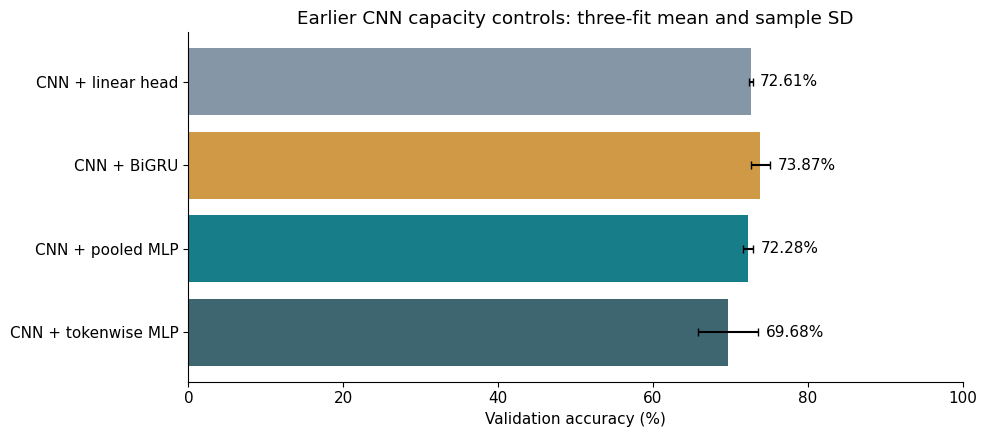

In [10]:
old=ROOT/"reports/mlp_controls_20261105"
old_groups=pd.read_csv(old/"comparison.csv");table(old_groups,3)
table(pd.read_csv(old/"runs.csv"),4)
table(pd.read_csv(old/"paired_differences.csv"),3)
fig,ax=plt.subplots(figsize=(10,4.5))
ax.barh(old_groups.label,old_groups.accuracy_percent,color=["#8597a6","#cf9945","#177e89","#3e6670"])
ax.errorbar(old_groups.accuracy_percent,range(len(old_groups)),xerr=old_groups.accuracy_sd_pp,fmt="none",color="black",capsize=3)
for index,row in old_groups.iterrows():ax.text(row.accuracy_percent+row.accuracy_sd_pp+1,index,f"{row.accuracy_percent:.2f}%",va="center")
ax.set_xlim(0,100);ax.invert_yaxis();ax.set_xlabel("Validation accuracy (%)")
ax.set_title("Earlier CNN capacity controls: three-fit mean and sample SD")
fig.tight_layout();fig.savefig(FIGURES/"restored_mlp_controls.png",dpi=180);plt.show()

## 6. Prediction changes and class-level recall

Repair/new-error counts are paired on the same recordings. Three training seeds are not three independent sets of validation audio. Each class has only seven or eight validation clips, so the class table is exploratory.

In [11]:
def predictions_for(model,seed,condition):
    return pd.read_csv(DATA/f"{model}_s{seed}_{condition}.csv").set_index("filename").sort_index()
pairs=[]
for condition in ["clean","snr_10"]:
    panns=predictions_for("panns_lr",0,condition)
    for seed in [101,202,303]:
        noise=predictions_for("noise_cnn",seed,condition).loc[panns.index]
        stats=paired_correctness((noise.prediction==noise.target).to_numpy(),(panns.prediction==panns.target).to_numpy())
        pairs.append({"Comparison":"PANNs versus noise CNN","Seed":seed,"Condition":condition,
                      "Repaired":stats["b_only_correct"],"New errors":stats["a_only_correct"],"Net correct":stats["net_correct"]})
        linear=predictions_for("factorized_linear",seed,condition)
        relu=predictions_for("mlp_relu",seed,condition).loc[linear.index]
        stats=paired_correctness((linear.prediction==linear.target).to_numpy(),(relu.prediction==relu.target).to_numpy())
        pairs.append({"Comparison":"ReLU versus factorized linear","Seed":seed,"Condition":condition,
                      "Repaired":stats["b_only_correct"],"New errors":stats["a_only_correct"],"Net correct":stats["net_correct"]})
table(pd.DataFrame(pairs),0)
classes=read_table("per_class.csv");classes["System / condition"]=classes.model.map(labels)+" / "+classes.condition
per_class=classes.pivot(index="category",columns="System / condition",values="mean_recall").reset_index()
table(per_class,3)

Comparison,Seed,Condition,Repaired,New errors,Net correct
PANNs versus noise CNN,101,clean,88,14,74
ReLU versus factorized linear,101,clean,5,10,-5
PANNs versus noise CNN,202,clean,83,15,68
ReLU versus factorized linear,202,clean,2,8,-6
PANNs versus noise CNN,303,clean,88,14,74
ReLU versus factorized linear,303,clean,1,6,-5
PANNs versus noise CNN,101,snr_10,86,55,31
ReLU versus factorized linear,101,snr_10,11,13,-2
PANNs versus noise CNN,202,snr_10,99,56,43
ReLU versus factorized linear,202,snr_10,11,12,-1


category,Noise-trained CNN / clean,Noise-trained CNN / snr_10,PANNs + ReLU MLP / clean,PANNs + ReLU MLP / snr_10,PANNs + factorized linear / clean,PANNs + factorized linear / snr_10,PANNs + logistic / clean,PANNs + logistic / snr_10
airplane,0.875,0.750,0.792,0.458,0.750,0.500,0.750,0.500
breathing,0.750,0.667,1.000,0.875,1.000,0.875,1.000,0.750
brushing_teeth,0.708,0.500,1.000,0.708,1.000,0.625,1.000,0.625
can_opening,0.917,0.833,1.000,0.458,1.000,0.542,1.000,0.625
car_horn,0.625,0.542,1.000,0.833,1.000,0.833,1.000,0.875
cat,0.667,0.667,1.000,0.958,1.000,1.000,1.000,1.000
chainsaw,0.833,0.833,0.750,0.625,0.750,0.625,0.750,0.625
chirping_birds,0.917,0.542,0.917,0.875,0.917,0.875,1.000,0.875
church_bells,0.875,0.708,0.917,0.875,0.917,0.875,0.875,0.875
clapping,0.667,0.875,0.917,0.792,0.917,0.792,1.000,0.875


### Exploratory clean-to-noisy transitions

These counts distinguish loss of previously correct predictions from the models' different starting capabilities. The common-clean-correct subset is defined separately for each noise-CNN fit; its intervals describe those selected subsets and do not replace the primary full-validation estimand.

In [12]:
from esc50_sound.prediction_errors import SourceBootstrap
transitions=[]
for model in labels:
    for seed in ([0] if model=="panns_lr" else [101,202,303]):
        clean=predictions_for(model,seed,"clean")
        noisy=predictions_for(model,seed,"snr_10").loc[clean.index]
        a=(clean.prediction==clean.target).to_numpy();b=(noisy.prediction==noisy.target).to_numpy()
        transitions.append({"System":labels[model],"Seed":seed,"Correct to correct":int((a&b).sum()),"Correct to wrong":int((a&~b).sum()),"Wrong to correct":int((~a&b).sum()),"Wrong to wrong":int((~a&~b).sum())})
transitions=pd.DataFrame(transitions);table(transitions,0)
transitions.to_csv(FIGURES/"clean_noise_transitions.csv",index=False)
metadata=pd.read_csv(ROOT/"data/ESC-50/meta/esc50.csv").set_index("filename")
common_rows=[]
pclean=predictions_for("panns_lr",0,"clean");pnoise=predictions_for("panns_lr",0,"snr_10").loc[pclean.index]
for seed in [101,202,303]:
    nclean=predictions_for("noise_cnn",seed,"clean").loc[pclean.index]
    nnoise=predictions_for("noise_cnn",seed,"snr_10").loc[pclean.index]
    selected=((pclean.prediction==pclean.target)&(nclean.prediction==nclean.target)).to_numpy()
    a=(pnoise.prediction==pnoise.target).to_numpy()[selected]
    b=(nnoise.prediction==nnoise.target).to_numpy()[selected]
    source_ids=metadata.loc[pclean.index[selected],"src_file"].astype(str).tolist()
    interval=SourceBootstrap(source_ids,4000,20261105).summarize(a.astype(float)-b.astype(float))
    common_rows.append({"Noise CNN seed":seed,"Common clean-correct clips":int(selected.sum()),"PANNs noisy accuracy (%)":100*a.mean(),"CNN noisy accuracy (%)":100*b.mean(),"Difference (pp)":interval["delta_accuracy_pp"],"95% lower (pp)":interval["source_bootstrap_low_pp"],"95% upper (pp)":interval["source_bootstrap_high_pp"]})
common_rows=pd.DataFrame(common_rows);table(common_rows,3)
common_rows.to_csv(FIGURES/"common_clean_correct.csv",index=False)

System,Seed,Correct to correct,Correct to wrong,Wrong to correct,Wrong to wrong
PANNs + logistic,0,265,98,13,22
Noise-trained CNN,101,221,68,26,83
Noise-trained CNN,202,217,78,18,85
Noise-trained CNN,303,232,57,21,88
PANNs + factorized linear,101,261,103,11,23
PANNs + factorized linear,202,260,106,11,21
PANNs + factorized linear,303,266,92,12,28
PANNs + ReLU MLP,101,260,99,10,29
PANNs + ReLU MLP,202,258,102,12,26
PANNs + ReLU MLP,303,250,103,14,31


Noise CNN seed,Common clean-correct clips,PANNs noisy accuracy (%),CNN noisy accuracy (%),Difference (pp),95% lower (pp),95% upper (pp)
101,275,76.364,76.364,0.000,-7.220,7.090
202,280,73.571,73.929,-0.357,-7.474,6.786
303,275,74.545,80.727,-6.182,-12.821,0.752


On subsets where PANNs and a particular noise-CNN were both correct on clean audio, PANNs-minus-CNN noisy accuracy is 0.00, −0.36 and −6.18 pp for seeds 101, 202 and 303. All three conditional intervals include zero. These selected-subset observations do not establish a stable PANNs advantage in retaining already correct predictions, and do not replace the full-validation primary comparison.

## 7. Research decision

- Keep the original PANNs logistic head as the stronger observed system among these transfer heads. This is a development decision, not independent model confirmation.
- Report both noisy accuracy and clean-to-noisy loss. PANNs wins the former; noise-trained CNNs lose fewer points in this matched panel.
- Restore and retain the earlier MLP controls. Their negative results and the new PANNs-head result concern different representations and training procedures.
- Do not extend this run into a width/activation/attention search. The fixed six-head stopping rule has been reached.
- The next higher-value question is performance on independent sources and realistic noise with compatible labels. A separate train-noise-adapted PANNs-head experiment would need a new fixed protocol; it was not executed here.

Sources: [PANNs paper](https://arxiv.org/abs/1912.10211), [official implementation](https://github.com/qiuqiangkong/audioset_tagging_cnn), [ESC-50](https://github.com/karolpiczak/ESC-50), and the project's prediction-level evidence. PANNs' original one-/three-layer transfer experiments motivate this question but use a different recipe and do not predetermine this result.

In [13]:
receipt={"completed_utc":datetime.now(timezone.utc).isoformat(),"status":summary["status"],
         "validation_clips":summary["clips"],"sources":summary["sources"],"primary_effect":summary["primary_effect"],
         "new_head_fits":summary["head_fits"],"head_epochs":summary["head_epochs"],"test_waveforms_read":summary["test_waveforms_read"],
         "saved_original_figure_count":22,"new_scientific_figures":4,"environment":summary["environment"]}
print(json.dumps(receipt,indent=2))

{
  "completed_utc": "2026-11-05T03:37:22.945323+00:00",
  "status": "completed",
  "validation_clips": 398,
  "sources": 295,
  "primary_effect": {
    "comparison": "panns_lr_minus_noise_cnn",
    "condition": "snr_10",
    "delta_pp": 8.291457286432161,
    "low_pp": 1.8271229985489683,
    "high_pp": 14.738730317136486
  },
  "new_head_fits": 6,
  "head_epochs": 100,
  "test_waveforms_read": 0,
  "saved_original_figure_count": 22,
  "new_scientific_figures": 4,
  "environment": {
    "python": "3.13.16",
    "torch": "2.11.0+cu130",
    "numpy": "2.4.6",
    "gpu": "Tesla T4"
  }
}
